# 18 - FilmAffinity TV ranking and mixed-feed policy

**Question:** Can a small change to the ranking policy improve the balance of movie and whole-series recommendations in one actual ten-title feed?

This is a bounded validation follow-up to [notebook 17](17_filmaffinity_hybrid_recommendations.ipynb). Reuse its frozen fitted basis and split, with a documented **metadata-only unit veto** applied consistently throughout notebook 18. Correct confirmed invalid whole-series units, then compare how movie and TV rankings are combined; do not retrain the model or modify notebook 17's saved artifacts.

There is no app update, new dataset, EASE search, LLM experiment, download, or paid API call in this study. The reserved FilmAffinity test feedback and all earlier MovieLens feedback stay closed.

## Prespecified boundary and data contract

- Verify the hashes of notebook 17's training and validation files and trusted fitted-model bundle before use. Keep the original source snapshots, split files, and saved model byte-unchanged. Reuse the fitted features and training-only prior rather than refitting them.
- Record the confirmed metadata-only unit-exclusion IDs and their source evidence in the study plan **before computing notebook 18 policy scores**. Apply this same veto to every candidate policy and corrected control: disable vetoed recommendation candidates, zero their profile-like columns, remove their invalid-unit ratings from validation targets, and recalculate training TV-like counts, history bins, and fixed task cohorts. Do not select exclusions from validation recommendation performance.
- A like remains **8/10 or higher**. Every training-rated title is excluded, including low ratings. Unobserved titles are not explicit dislikes.
- Read only the frozen training and validation artifacts needed for this follow-up. Do not reread the full raw ratings file or load reserved-test feedback.
- Keep the movie branch's model and weights fixed at notebook 17's saved best personalized hybrid, using profiles and candidate eligibility after the shared unit veto. Within TV, compare normalized popularity with that saved personalized ranking signal, with both normalized over **eligible unseen TV candidates**.
- TV blend weights are fixed in advance: **0, 0.25, 0.5, and 1**, plus **training TV-like count / (training TV-like count + 5)**. Weight 0 is popularity; weight 1 is personalized. The adaptive weight uses only training TV likes, never validation history or targets.
- Cross each of those five TV choices with **2, 4, or 6 TV positions in a total of ten recommendations**. Use even proportional interleaving and preserve each branch's original item ordering. Keep deterministic ties and the same treatment of unavailable branches.
- This makes **15 candidate policies**, plus the **Corrected popularity control** and **Corrected hybrid control**, for **17 comparisons**. These controls use notebook 17's saved model definitions under notebook 18's corrected catalog, profiles, labels, and cohorts; they are not the unchanged original notebook 17 rankings.
- First reproduce the original notebook 17 mixed-control metrics on its original artifacts as a separate regression check. Keep that check separate from policy selection and from the corrected-control leaderboard.

The hypothesis is that TV popularity may be more useful with limited TV history and personalization may help with more history. This is a hypothesis to measure, not an assumed result. Type allocation is a ranking policy, not a predicted probability that a user wants TV.

## Prespecified selection and diagnostics

Select a policy using the **balanced mean of movie Recall@10 and whole-series Recall@10 measured from the same actual mixed top-ten lists**. After the common metadata-only unit veto, fix each domain's eligible user cohort once and use it for every policy and both corrected controls; cohort membership must not depend on which recommendations a policy returns.

Remove only the documented invalid-unit validation ratings. Keep **all remaining relevant validation titles** in Recall and ideal-DCG denominators, including titles absent from the eligible candidate catalog. Report mixed Recall@10/NDCG@10, movie and TV metrics from the actual mixed list, and TV exposure. Break results down by **0, 1-4, and 5+ training TV likes**, recalculated after the veto, with cohort sizes and coverage alongside averages.

Separate movie-only and TV-only shelves are diagnostic comparisons. A ten-item shelf gives that domain ten slots; a mixed list allocates a shared ten-slot budget. Shelf results therefore cannot be presented as equivalent to the mixed-feed outcome.

Before interpreting unit labels, inspect a small manual source-unit spotcheck selected using training candidates only. A confirmed source-unit error triggers the documented shared veto; the remaining labels are still provisional. This is a focused check of source evidence, not a representative population error estimate or proof that all retained entries are whole series.

**Pre-score audit finding:** FilmAffinity item **745751, Stranger Things**, explicitly directs users to separately voted later seasons from season 2 onward. Treat this source entry as season 1 rather than a whole-series unit, and include it in the confirmed unit exclusions. Inspect the saved evidence and any additional confirmed exclusions below.

In [1]:
from pathlib import Path
import sys

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "scripts" / "filmaffinity_experiment.py").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Run this notebook from inside the movie-recommendation-system project.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts.filmaffinity_ranking_policy import run_experiment

report = run_experiment(ROOT)

Verifying frozen notebook17 inputs and reviewing source-unit eligibility...
Source spot-check: 12 fixed entries; {'source_supports_whole_series': 8, 'ambiguous_source_unit': 3, 'source_indicates_season_or_episode': 1}
Reviewed 204 explicit-marker hits across 1727 training series candidates; confirmed 12 season-scoped units.
Reproducing original17 mixed controls before the metadata-only veto...
Both original17 controls reproduced; scoring the corrected eligibility study...
Validated 128/4,143 corrected-cohort users, 17 policies.
Validated 1,024/4,143 corrected-cohort users, 17 policies.
Validated 2,048/4,143 corrected-cohort users, 17 policies.
Validated 3,072/4,143 corrected-cohort users, 17 policies.
Validated 4,096/4,143 corrected-cohort users, 17 policies.
Validated 4,143/4,143 corrected-cohort users, 17 policies.
Selected TV alpha=0.5; 6 TV + 4 movies on corrected validation; finished in 89.8s.


## What this run found

The source review found **12 confirmed season-scoped entries**, including Stranger Things' separately rated first and second seasons. They are disabled for every policy: excluded from candidates and liked profiles, and removed from validation target labels. The 12-title spot-check itself found 8 source-supported whole-series entries, 3 ambiguous entries, and 1 season entry; marker-based review then examined 204 descriptions across all 1,727 frozen series candidates. This is a source-only review and can miss differently worded errors. Unflagged titles are not independently verified.

The corrected study has **1,715 eligible series candidates**, **8,995 movies**, **4,143 validation-positive users**, and **972 TV-positive users**. Original17 controls reproduced before correction; all rows below use the same corrected18 cohorts. The inherited training-user cohort is unchanged, although its original minimum-history counts included now-vetoed events. The model's original training basis is retained rather than refit.

All of the following numbers are Recall@10 from the **same actual mixed ten-title lists**, using each domain's fixed eligible user cohort:

| Policy | Movie recall | TV recall | Overall mixed recall | Balanced domain recall |
|---|---:|---:|---:|---:|
| Corrected original hybrid | 4.79% | 0.47% | **4.35%** | 2.63% |
| 50/50 TV blend; 2 TV + 8 movies | 4.09% | 5.25% | 4.29% | 4.67% |
| 50/50 TV blend; 4 TV + 6 movies | 3.20% | 8.90% | 3.98% | 6.05% |
| 50/50 TV blend; 6 TV + 4 movies | 2.41% | **11.20%** | 3.53% | **6.81%** |

**The selected experimental policy uses a 50/50 TV popularity/personalization blend and six TV slots.** It wins the prespecified equal-domain objective, but movie recall roughly halves and overall mixed recall falls. This is a deliberate allocation tradeoff, not an across-the-board accuracy improvement or a recommendation to force six TV slots in the app.

The 2-TV/8-movie policy is a useful alternative to inspect: its overall mixed recall is close to the original control while giving TV titles more opportunity. It was not selected by the primary balanced objective. Separate movie and TV shelves may remain useful product choices when the user knows what they want to watch.

**TV personalization adds a small signal when anchored to popularity.** On the separate ten-TV shelf, 25% personal/75% popularity has the highest observed recall, **15.65%**, versus **15.34%** for popularity alone and **7.63%** for personal-only. This small validation difference needs confirmation. The best weight for a full TV shelf differs from the best weight when only its first six titles are used in a mixed list. History-based weighting did not beat the fixed 50/50 blend on the primary objective, and history-bin differences are observational.

These are repeated-validation findings. Date proxies, review selection, provisional title units, and the original fitted basis limit generalization. The existing app is unchanged, no paid API was called, and the reserved test remains unused. Before a final evaluation, freeze the policy, unit exclusions, candidate rule and objective; use the same metadata-only exclusions when defining eligible test targets. A blinded user study should then assess usefulness without revealing model identity or public title scores.


## Frozen fitted basis, unit veto, and study plan

The following records come from this run rather than from handwritten results. Review the original input identities, the pre-score unit-veto list, the selection rule, the corrected fixed task cohorts, and the policy definitions before reading the leaderboards.

In [2]:
from IPython.display import display
import pandas as pd

OUTPUT = ROOT / "data" / "processed" / "notebook18_filmaffinity"

display(report.get("scope", {"status": "No scope section was supplied by the helper."}))
display(report.get("study_plan", {"status": "No study-plan section was supplied by the helper."}))
display(report.get("dataset", {"status": "No dataset section was supplied by the helper."}))

{'evaluation_split': 'validation',
 'test_feedback_read': False,
 'raw_ratings_read': False,
 'model_refitted': False,
 'app_changed': False,
 'paid_api_calls': False,
 'correction': 'Metadata-only unit veto applies equally to all18 profiles, candidates and labels; exact17 controls reproduced separately before correction',
 'comparison': 'Primary objective is actual mixed-list domain recall, unlike17 separate-shelf objective; corrected cohorts differ from17',
 'basis_limitation': 'CF/content/prior were fit on original17 training data, including now-vetoed entries; encoders and features are not retrained',
 'source_limitations': 'Provisional unit inference, source-scoped manual audit, review-associated scores, current metadata and review-date proxies remain',
 'cohort_eligibility': 'Inherited17 retrospective users; original minimum history/date counts included now-vetoed events, so no new minimum-history claim after cleanup',
 'selection_limitations': 'Repeated use of the same validatio

{'experiment': 'notebook18_tv_ranking_policy',
 'like_threshold': 8.0,
 'policies': [{'policy': 'Corrected hybrid control',
   'kind': 'hybrid_control',
   'alpha': None,
   'tv_slots': None},
  {'policy': 'Corrected popularity control',
   'kind': 'popularity_control',
   'alpha': None,
   'tv_slots': None},
  {'policy': 'TV alpha=0; 2 TV + 8 movies',
   'kind': 'allocated',
   'alpha': 0.0,
   'tv_slots': 2},
  {'policy': 'TV alpha=0; 4 TV + 6 movies',
   'kind': 'allocated',
   'alpha': 0.0,
   'tv_slots': 4},
  {'policy': 'TV alpha=0; 6 TV + 4 movies',
   'kind': 'allocated',
   'alpha': 0.0,
   'tv_slots': 6},
  {'policy': 'TV alpha=0.25; 2 TV + 8 movies',
   'kind': 'allocated',
   'alpha': 0.25,
   'tv_slots': 2},
  {'policy': 'TV alpha=0.25; 4 TV + 6 movies',
   'kind': 'allocated',
   'alpha': 0.25,
   'tv_slots': 4},
  {'policy': 'TV alpha=0.25; 6 TV + 4 movies',
   'kind': 'allocated',
   'alpha': 0.25,
   'tv_slots': 6},
  {'policy': 'TV alpha=0.5; 2 TV + 8 movies',
   'kin

{'training_users': 5505,
 'eligible_candidate_count': 10710,
 'eligible_movie_candidates': 8995,
 'eligible_series_candidates': 1715,
 'original_validation_rows': 57995,
 'eligible_validation_rows': 57919,
 'eligible_validation_positive_users': 4143,
 'n_policies': 17}

## Provisional source-unit spotcheck and coverage

FilmAffinity item units were inferred in the earlier source audit. Series, seasons, episodes, miniseries, and films can have inconsistent or ambiguous source descriptions. The training-selected source-unit check identified confirmed errors, including the Stranger Things season-1 entry, which this follow-up explicitly vetoes. The saved exclusion table records IDs and source evidence. The small sample cannot establish the accuracy of every remaining TV label.

Coverage describes which valid-unit validation targets the training catalog can retrieve after the shared veto. Confirmed invalid-unit ratings are removed from the targets consistently for every policy and control; all other unavailable targets still contribute to the evaluation denominator. Fitted vocabularies and feature weights still come from notebook 17's original fit, which included the excluded items' metadata. This is a documented eligibility and profile correction, not a clean refit of the model.

In [3]:
audit_summary = report['unit_spotcheck']
display({
    'sample_counts': audit_summary['counts'],
    'sample_design': audit_summary['sample_design'],
    'training_series_candidates': audit_summary['full_catalog_marker_review']['training_whole_series_candidates'],
    'marker_descriptions_reviewed': audit_summary['full_catalog_marker_review']['flagged_entries_reviewed'],
    'remaining_limit': audit_summary['full_catalog_marker_review']['not_exhaustive'],
})

def show_saved_table(filename):
    frame = pd.read_csv(OUTPUT / filename)
    display(frame)
    return frame

unit_spotcheck_table = show_saved_table('unit_spotcheck.csv')
display(report['unit_corrections'])
confirmed_exclusions_table = show_saved_table('confirmed_unit_exclusions.csv')
display(pd.DataFrame(report['coverage']))


{'sample_counts': {'source_supports_whole_series': 8,
  'ambiguous_source_unit': 3,
  'source_indicates_season_or_episode': 1},
 'sample_design': {'seed': 42,
  'sample_size': 12,
  'strata': [{'confidence': 'high',
    'catalog_entries': 702,
    'low_support_train_like_cutoff': 1.0,
    'top_sample': 3,
    'low_support_sample': 3},
   {'confidence': 'medium',
    'catalog_entries': 1025,
    'low_support_train_like_cutoff': 0.0,
    'top_sample': 3,
    'low_support_sample': 3}],
  'rule': 'Within high/medium confidence: three largest training-like counts (item ID ties), then three smallest SHA256(42|confidence|item_id) in the remaining at-or-below-median training-like pool.',
  'selection_before_source_reading': True},
 'training_series_candidates': 1727,
 'marker_descriptions_reviewed': 204,
 'remaining_limit': 'Marker search can miss implicit or differently worded scope errors; unflagged entries are not verified.'}

,item_id,title,original_title,confidence,train_likes,sampling_stratum,assessment,review_note,evidence_excerpt
0,film489970,Breaking Bad,Breaking Bad,high,125,top_training_likes,source_supports_whole_series,Header explicitly describes the full five-seas...,Serie de TV (2008-2013). 5 temporadas. 62 epis...
1,film372160,Los Simpson,The Simpsons,high,116,top_training_likes,source_supports_whole_series,Open-ended series header spans 36 seasons rath...,Serie de TV (1989-). 36 temporadas.
2,film370639,Perdidos (Lost),Lostaka,high,93,top_training_likes,source_supports_whole_series,Header explicitly describes the six-season run...,Serie de TV (2004-2010). 6 temporadas. 121 epi...
3,film392777,Una historia de crímenes,Una historia de crímenes,high,0,low_support_seed42,source_supports_whole_series,The source groups three seasons and 18 episode...,3 temporadas. 18 episodios.
4,film667520,Yo y el mundo,Boy Meets World,high,1,low_support_seed42,source_supports_whole_series,The seven-season run is identified explicitly ...,Serie de TV (1993-2000). 7 temporadas. 158 epi...
5,film231065,Todos mienten,Todos mienten,high,0,low_support_seed42,source_supports_whole_series,Multiyear series header; no particular-season ...,Serie de TV (2022-2024).
6,film640188,Hermanos de sangre,Band of Brothers,medium,54,top_training_likes,source_supports_whole_series,The miniseries header and complete numbered ep...,Miniserie de TV. 10 episodios.
7,film624827,Chernobyl,Chernobyl,medium,46,top_training_likes,source_supports_whole_series,The source identifies a five-episode miniserie...,Miniserie de TV (2019). 5 episodios.
8,film745751,Stranger Things,Stranger Things,medium,39,top_training_likes,source_indicates_season_or_episode,The eight-episode 2016 entry explicitly sends ...,Las Temporadas posteriores (2 en adelante) pue...
9,film662558,"Conspiración, traición y muerte","Gunpowder, Treason & Plot",medium,0,low_support_seed42,ambiguous_source_unit,The miniseries label is consistent with a whol...,Miniserie sobre la controvertida reina de Escocia


{'excluded_item_ids': ['film151087',
  'film196789',
  'film410609',
  'film442387',
  'film468690',
  'film528128',
  'film539332',
  'film662961',
  'film664726',
  'film710523',
  'film716612',
  'film745751'],
 'excluded_candidate_count': 12,
 'removed_training_likes': 98,
 'removed_validation_rows': 76,
 'removed_validation_likes': 32,
 'policy': 'Metadata-only exclusions frozen before scoring; applied to all18 profiles, candidates and eligible labels.',
 'fitted_basis': 'Original17 CF/content/quality basis retained; no assertion that all training labels or metadata are now clean.'}

,item_id,title,original_title,confidence,train_likes,assessment,reason,evidence_excerpt
0,film151087,Stranger Things 2,Stranger Things 2,medium,18,confirmed_season_scoped_unit,The source directly identifies this entry as S...,La segunda temporada de 'Stranger Things'
1,film196789,American Horror Story: Asylum,American Horror Story: Asylum,high,16,confirmed_season_scoped_unit,The source directly identifies Asylum as Ameri...,"Segunda temporada de la serie ""American Horror..."
2,film410609,Por trece razones: ¿Quién mató a Bryce Walker?,13 Reasons Why: Who killed Bryce Walker?,medium,0,confirmed_season_scoped_unit,The named entry is explicitly the third season...,"Tercera temporada de ""Por 13 razones"""
3,film442387,Feud: Capote vs. The Swans,Feud: Capote vs. The Swans,medium,1,confirmed_season_scoped_unit,The source explicitly identifies this Feud ent...,Segunda temporada de la serie de antología de ...
4,film468690,Homecoming 2,Homecoming 2,medium,0,confirmed_season_scoped_unit,Homecoming 2 is described as the second-season...,La segunda temporada es una historia totalment...
5,film528128,"Love, Death + Robots. Volumen 2","Love, Death + Robots. Vol. 2",medium,4,confirmed_season_scoped_unit,Volume 2 is explicitly the second season of th...,Temporada 2 de la serie antológica de cortos
6,film539332,Good Omens 2,Good Omens 2,medium,0,confirmed_season_scoped_unit,Good Omens 2 is explicitly the second season o...,Segunda temporada de la miniserie ‘Good Omens’...
7,film662961,JoJo's Bizarre Adventure,Jojo no Kimyô na Bôken (JoJo's Bizarre Adventu...,high,1,confirmed_season_scoped_unit,The 26-episode Phantom Blood/Battle Tendency e...,La primera temporada abarca dos arcos argument...
8,film664726,Condena,Time,medium,8,confirmed_season_scoped_unit,The three-episode Time entry is separate from ...,"Time tiene una segunda temporada 2T con trama,..."
9,film710523,True Detective II,True Detective IIaka,medium,10,confirmed_season_scoped_unit,True Detective II is explicitly the second sea...,Segunda temporada de la popular serie de la HBO


,task,users,positives,available,mean_available_fraction,mean_recall_ceiling_at_10
0,mixed,4143,17378,17184,0.988158,0.956068
1,movie,3830,15625,15520,0.993530,0.962195
2,whole_series,972,1753,1664,0.958303,0.956758


## Actual mixed top-ten policy comparison

Every row below must use the same corrected candidate eligibility, profiles, validation labels, and fixed movie and TV cohorts. Use the balanced domain-recall objective to select a policy, then inspect mixed-list accuracy and exposure together. Greater TV exposure alone does not demonstrate more relevant recommendations.

The Corrected popularity control and Corrected hybrid control provide a reference for introducing explicit type allocation after the common metadata-only unit veto. The original notebook 17 control reproduction is a separate regression check. Corrected results are not directly comparable to the old raw scores because item eligibility, target labels, profiles, and cohorts have changed. An apparent gain on this validation set is exploratory evidence for the policy and objective tested here.

In [4]:
policy_leaderboard_table = show_saved_table("policy_leaderboard.csv")
display(report.get("best_policy", {"status": "No selected-policy section was supplied by the helper."}))
display(report.get("controls", {"status": "No control summaries were supplied by the helper."}))

,policy,kind,alpha,tv_slots,mixed_users,movie_users,tv_users,tv_slot_share,fraction_users_with_tv,mixed_recall_at_10,mixed_ndcg_at_10,movie_recall_at_10,movie_ndcg_at_10,tv_recall_at_10,tv_ndcg_at_10,balanced_mixed_recall_at_10
0,TV alpha=0.5; 6 TV + 4 movies,allocated,0.5,6.0,4143,3830,972,0.600000,1.000000,0.035297,0.027041,0.024147,0.020924,0.112027,0.053098,0.068087
1,TV alpha=history; 6 TV + 4 movies,allocated,history_gate,6.0,4143,3830,972,0.600000,1.000000,0.035060,0.026751,0.024147,0.020924,0.111501,0.051928,0.067824
2,TV alpha=0.25; 6 TV + 4 movies,allocated,0.25,6.0,4143,3830,972,0.600000,1.000000,0.034940,0.026673,0.024147,0.020924,0.108808,0.050672,0.066478
3,TV alpha=0; 6 TV + 4 movies,allocated,0.0,6.0,4143,3830,972,0.600000,1.000000,0.034508,0.026399,0.024147,0.020924,0.105737,0.049069,0.064942
4,TV alpha=0.5; 4 TV + 6 movies,allocated,0.5,4.0,4143,3830,972,0.400000,1.000000,0.039758,0.030416,0.032011,0.027134,0.089031,0.037809,0.060521
5,TV alpha=history; 4 TV + 6 movies,allocated,history_gate,4.0,4143,3830,972,0.400000,1.000000,0.039312,0.030084,0.032011,0.027134,0.086312,0.036080,0.059162
6,TV alpha=0.25; 4 TV + 6 movies,allocated,0.25,4.0,4143,3830,972,0.400000,1.000000,0.039219,0.030027,0.032011,0.027134,0.084941,0.035414,0.058476
7,TV alpha=0; 4 TV + 6 movies,allocated,0.0,4.0,4143,3830,972,0.400000,1.000000,0.039179,0.029962,0.032011,0.027134,0.084426,0.034977,0.058219
8,TV alpha=0.5; 2 TV + 8 movies,allocated,0.5,2.0,4143,3830,972,0.200000,1.000000,0.042900,0.032730,0.040924,0.032834,0.052463,0.019397,0.046693
9,TV alpha=history; 2 TV + 8 movies,allocated,history_gate,2.0,4143,3830,972,0.200000,1.000000,0.042211,0.032413,0.040924,0.032834,0.045816,0.017264,0.043370


{'policy': 'TV alpha=0.5; 6 TV + 4 movies',
 'kind': 'allocated',
 'alpha': 0.5,
 'tv_slots': 6.0,
 'mixed_users': 4143,
 'movie_users': 3830,
 'tv_users': 972,
 'tv_slot_share': 0.6,
 'fraction_users_with_tv': 1.0,
 'mixed_recall_at_10': 0.035297102246905604,
 'mixed_ndcg_at_10': 0.027040738319250048,
 'movie_recall_at_10': 0.024147284370743146,
 'movie_ndcg_at_10': 0.02092423225028482,
 'tv_recall_at_10': 0.11202705045297637,
 'tv_ndcg_at_10': 0.05309804510222291,
 'balanced_mixed_recall_at_10': 0.06808716741185976}

[{'policy': 'Corrected hybrid control',
  'kind': 'hybrid_control',
  'alpha': None,
  'tv_slots': None,
  'mixed_users': 4143,
  'movie_users': 3830,
  'tv_users': 972,
  'tv_slot_share': 0.06886314265025344,
  'fraction_users_with_tv': 0.22592324402606806,
  'mixed_recall_at_10': 0.043511983277543236,
  'mixed_ndcg_at_10': 0.033901233888426904,
  'movie_recall_at_10': 0.04791717367415061,
  'movie_ndcg_at_10': 0.03663381685059309,
  'tv_recall_at_10': 0.004655349794238683,
  'tv_ndcg_at_10': 0.0029666561725984297,
  'balanced_mixed_recall_at_10': 0.026286261734194648},
 {'policy': 'Corrected popularity control',
  'kind': 'popularity_control',
  'alpha': None,
  'tv_slots': None,
  'mixed_users': 4143,
  'movie_users': 3830,
  'tv_users': 972,
  'tv_slot_share': 0.0002413709872073377,
  'fraction_users_with_tv': 0.0019309678976587015,
  'mixed_recall_at_10': 0.027836063886902143,
  'mixed_ndcg_at_10': 0.01952752469351362,
  'movie_recall_at_10': 0.03167359553416171,
  'movie_ndcg_at_

## Accuracy and TV-exposure tradeoff

Interpret this plot using the actual mixed-list budget of ten titles. Inspect the labeled controls and selected policy rather than treating TV slot allocation as a calibrated preference probability.

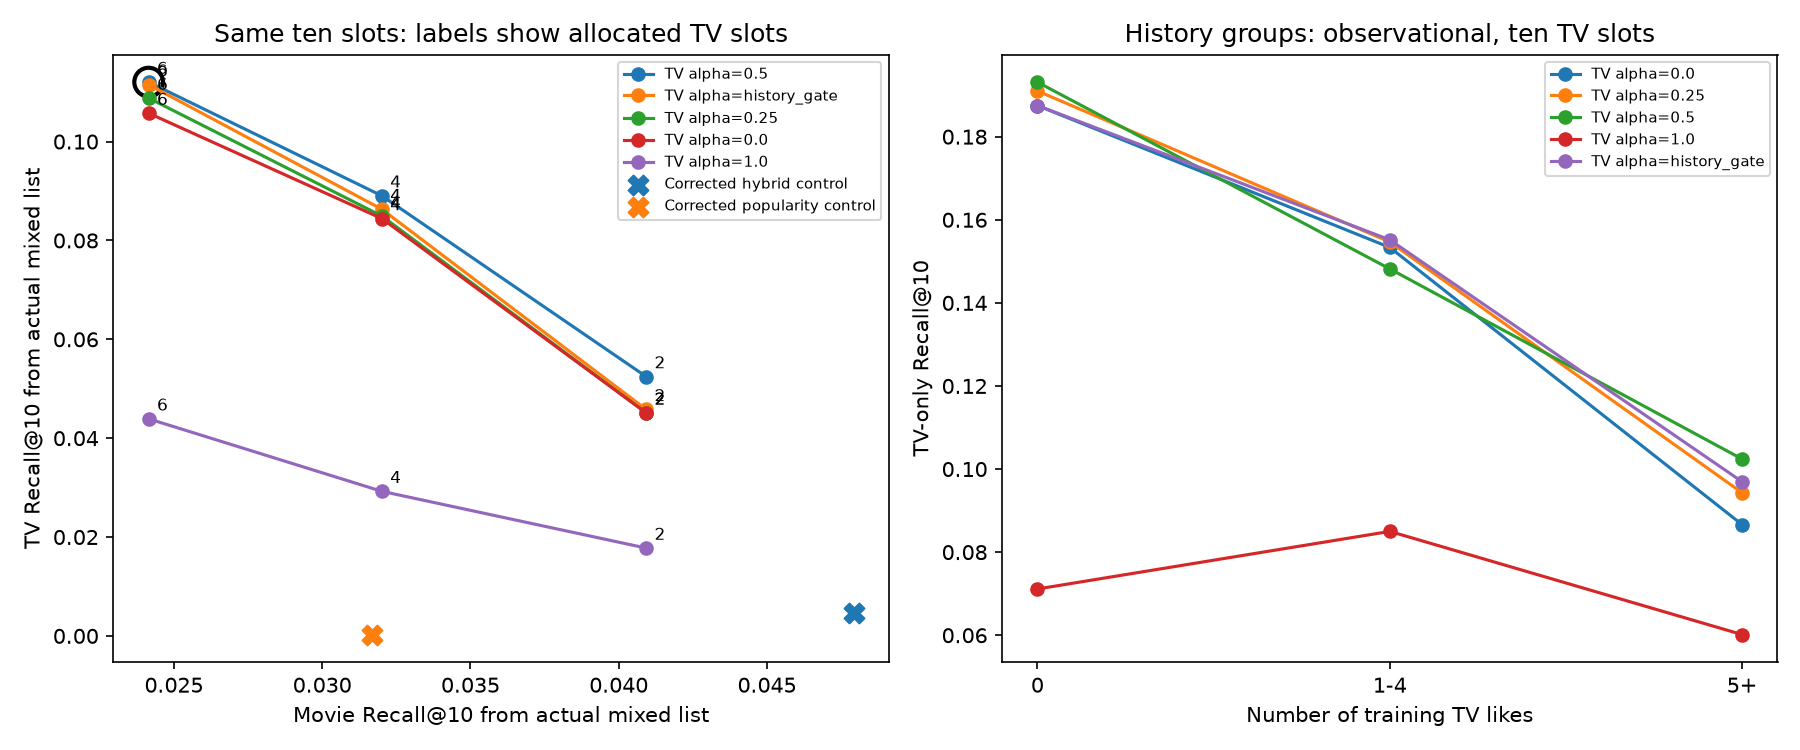

In [5]:
from IPython.display import Image

tradeoff_path = OUTPUT / "mixed_policy_tradeoff.png"
if tradeoff_path.is_file():
    display(Image(filename=str(tradeoff_path)))
else:
    print("The mixed-policy tradeoff plot was not produced by this run.")

## Results by training TV-history size

The **0, 1-4, and 5+** bins use only the user's valid-unit training TV likes, recalculated after removing vetoed profile likes. Validation likes determine corrected evaluation targets, not the adaptive policy's history count. Read the cohort sizes and available-target coverage with each bin's metrics.

A small or empty subgroup cannot support a broad conclusion about cold start or cross-domain transfer. The adaptive weight is useful only if its measured tradeoff supports the hypothesis.

In [6]:
history_bin_table = show_saved_table('history_bin_metrics.csv')
display(pd.DataFrame(report['history_bins']))


,view,policy,history_bin,mixed_users,movie_users,tv_users,tv_slot_share,fraction_users_with_tv,mixed_recall_at_10,mixed_ndcg_at_10,movie_recall_at_10,movie_ndcg_at_10,tv_recall_at_10,tv_ndcg_at_10,balanced_mixed_recall_at_10
0,actual mixed list,Corrected hybrid control,0,2736.0,2611.0,320,0.025475,0.141447,0.044042,0.031193,0.046799,0.032793,0.003125,0.001972,0.024962
1,actual mixed list,Corrected hybrid control,1-4,1206.0,1040.0,489,0.138557,0.373964,0.045817,0.038005,0.055055,0.044044,0.005112,0.003485,0.030084
2,actual mixed list,Corrected hybrid control,5+,201.0,179.0,163,0.241294,0.487562,0.022468,0.046140,0.022751,0.049600,0.006288,0.003364,0.014520
3,actual mixed list,Corrected popularity control,0,2736.0,2611.0,320,0.000183,0.001096,0.029514,0.018377,0.032117,0.019825,0.000000,0.000000,0.016058
4,actual mixed list,Corrected popularity control,1-4,1206.0,1040.0,489,0.000166,0.001658,0.026531,0.020967,0.033158,0.025315,0.000000,0.000000,0.016579
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,TV-only shelf,TV alpha=1.0,1-4,NaN,NaN,489,NaN,NaN,NaN,NaN,NaN,NaN,0.084989,0.044243,NaN
62,TV-only shelf,TV alpha=1.0,5+,NaN,NaN,163,NaN,NaN,NaN,NaN,NaN,NaN,0.060147,0.037766,NaN
63,TV-only shelf,TV alpha=history_gate,0,NaN,NaN,320,NaN,NaN,NaN,NaN,NaN,NaN,0.187500,0.104981,NaN
64,TV-only shelf,TV alpha=history_gate,1-4,NaN,NaN,489,NaN,NaN,NaN,NaN,NaN,NaN,0.155166,0.088481,NaN


,view,policy,history_bin,mixed_users,movie_users,tv_users,tv_slot_share,fraction_users_with_tv,mixed_recall_at_10,mixed_ndcg_at_10,movie_recall_at_10,movie_ndcg_at_10,tv_recall_at_10,tv_ndcg_at_10,balanced_mixed_recall_at_10
0,actual mixed list,Corrected hybrid control,0,2736.0,2611.0,320,0.025475,0.141447,0.044042,0.031193,0.046799,0.032793,0.003125,0.001972,0.024962
1,actual mixed list,Corrected hybrid control,1-4,1206.0,1040.0,489,0.138557,0.373964,0.045817,0.038005,0.055055,0.044044,0.005112,0.003485,0.030084
2,actual mixed list,Corrected hybrid control,5+,201.0,179.0,163,0.241294,0.487562,0.022468,0.046140,0.022751,0.049600,0.006288,0.003364,0.014520
3,actual mixed list,Corrected popularity control,0,2736.0,2611.0,320,0.000183,0.001096,0.029514,0.018377,0.032117,0.019825,0.000000,0.000000,0.016058
4,actual mixed list,Corrected popularity control,1-4,1206.0,1040.0,489,0.000166,0.001658,0.026531,0.020967,0.033158,0.025315,0.000000,0.000000,0.016579
5,actual mixed list,Corrected popularity control,5+,201.0,179.0,163,0.001493,0.014925,0.012824,0.026559,0.016587,0.029776,0.001534,0.000853,0.009061
6,actual mixed list,TV alpha=0.5; 6 TV + 4 movies,0,2736.0,2611.0,320,0.600000,1.000000,0.030323,0.022062,0.022330,0.018060,0.131380,0.060100,0.076855
7,actual mixed list,TV alpha=0.5; 6 TV + 4 movies,1-4,1206.0,1040.0,489,0.600000,1.000000,0.048248,0.035932,0.030751,0.026460,0.111710,0.053434,0.071230
8,actual mixed list,TV alpha=0.5; 6 TV + 4 movies,5+,201.0,179.0,163,0.600000,1.000000,0.025305,0.041470,0.012287,0.030544,0.074984,0.038344,0.043636


## Separate shelves: a different slot budget

The following movie-only and TV-only shelf diagnostics each devote their own recommendation budget to one domain. They help identify whether candidate ranking or mixed-feed allocation limits retrieval, but they do not share the mixed feed's ten total positions.

Do not compare a TV-only Recall@10 directly with TV recall from a mixed list as though the TV budgets were equal.

In [7]:
shelf_leaderboard_table = show_saved_table("shelf_leaderboard.csv")
display(report.get("best_shelf_model", {"status": "No shelf-model summary was supplied by the helper."}))

,tv_model,alpha,tv_users,movie_users,tv_recall_at_10,tv_ndcg_at_10,movie_recall_at_10,movie_ndcg_at_10
0,TV alpha=0.25,0.25,972,3830,0.156498,0.089369,0.048875,0.037087
1,TV alpha=history_gate,history_gate,972,3830,0.156044,0.089752,0.048875,0.037087
2,TV alpha=0.5,0.5,972,3830,0.155299,0.091276,0.048875,0.037087
3,TV alpha=0.0,0.0,972,3830,0.153394,0.086824,0.048875,0.037087
4,TV alpha=1.0,1.0,972,3830,0.076260,0.039643,0.048875,0.037087


{'tv_model': 'TV alpha=0.25',
 'alpha': '0.25',
 'tv_users': 972,
 'movie_users': 3830,
 'tv_recall_at_10': 0.15649843983177317,
 'tv_ndcg_at_10': 0.08936877097949898,
 'movie_recall_at_10': 0.04887452789521241,
 'movie_ndcg_at_10': 0.037087006206272234}

## Interpretation and limits

This follow-up selects a **ranking policy under a new mixed-feed objective**. Notebook 17's earlier primary objective used domain-specific ranking tasks; changing the objective changes what is optimized. Results here do not retroactively establish that notebook 17 selected the best mixed-feed policy.

The split follows review-publication date groups. These dates are proxies for preference-recording time, not verified rating timestamps. Catalog metadata is a current snapshot, and the earlier heuristic whole-TV-unit labels retain their limitations. The small source-unit spotcheck does not remove those limitations.

The original notebook 17 snapshots, split, and model remain byte-unchanged. Notebook 18 reuses that fitted basis with a documented metadata-only unit veto, so its valid candidate set, profile likes, validation labels, history bins, and cohorts differ from the original experiment. The fitted vocabularies still include metadata from excluded items. Differences among notebook 18 rows concern its common corrected population and ranking policies, not a newly trained model; differences from the old raw notebook 17 scores cannot be attributed solely to ranking policy. No conclusion about beating an LLM, the earlier MovieLens models, or live app recommendations follows from these results.

After bounded validation selection, a final untouched holdout or prospective user evaluation is needed to assess generalization. Keep the reserved test closed throughout this notebook. Do not repeatedly retune policies against it.

In [8]:
display(report.get("files", {"status": "No output-file manifest was supplied by the helper."}))
print("Output directory:", OUTPUT)

Output directory: C:\Users\clark\OneDrive\Documents\Projects\movie-recommendation-system\data\processed\notebook18_filmaffinity


{'policy_leaderboard.csv': 'f99c544cd57d1fbe1c5750ff1904d23d1508a444451856d289c934b77077bb76',
 'shelf_leaderboard.csv': '45d842daee5f43b68d202ec9ad172fe1cd23cd235ae6bc791975f0b1e853abdc',
 'policy_per_user.csv': '783e5d2f7af210d18d5c7ab9e7d0e49974fb0df3ef468adc3bb68fa2bafc1407',
 'shelf_per_user.csv': '59d8bc18d6efbfae754b528644791f94363fc4c6ad729531031cfc28352afb19',
 'history_bin_metrics.csv': '36f6ebd68964443b5335ea2cf2cd26f75f30f0942e91b827911f5e658f2e6f84',
 'coverage.csv': '2705600285b8bd312ceb145edffcb9808649b77e2ca20aefdfe06fe93b02bdc5',
 'recommendation_examples.csv': '4d7d9630b9f63ba4b7bf4b310d62c762a29a705420b13c1e40048ce0a6ee7c3b',
 'paired_validation_intervals.csv': 'ba38cce1920b412faf7d837b1f90b7d3ab1d326a52c8ff8c4329069614082013',
 'study_plan.json': '6b06f6637238a10a840366583c3b19c3c2db8c19a0a726187ad65377187017f1',
 'selected_policy.json': '3503eb45c19cd1284f21857e59fe3d6b0196b53b8ad096e16328bd22e5c79683',
 'mixed_policy_tradeoff.png': 'a2fafd5cb3e2acd56fa08a3263ae8a0

## Reload and check the selected policy

The saved selection references the trusted frozen model and the confirmed unit exclusions. Reconstruct three fixed training profiles (the first user ID in each history bin) and verify that saved-policy inference reproduces the per-user evaluation metrics. No test feedback is loaded. These checks verify implementation consistency, not independent generalization.

The last example is an editable illustrative new-user profile. Scores of 8 or more form likes; all rated titles, including lower scores, are excluded. Whole-series eligibility remains provisional beyond the confirmed exclusions.


In [9]:
import json
import numpy as np
from scripts.filmaffinity_ranking_policy import load_selected_policy, recommend_policy
from scripts.filmaffinity_experiment import ranking_metrics, sha256_file

loaded_policy = load_selected_policy(ROOT)
selected_rows = pd.read_csv(OUTPUT / 'policy_per_user.csv')
selected_rows = selected_rows.loc[selected_rows['policy'] == report['best_policy']['policy']]
frozen_training = pd.read_csv(ROOT / 'data/processed/notebook17_filmaffinity/train.csv')
frozen_validation = pd.read_csv(ROOT / 'data/processed/notebook17_filmaffinity/validation.csv')
unit_map = pd.read_csv(ROOT / 'data/processed/notebook16_dataset_audit/filmaffinity_catalog_units.csv', usecols=['item_id', 'unit'])
frozen_validation = frozen_validation.merge(unit_map, on='item_id', validate='many_to_one')
banned_ids = set(report['unit_corrections']['excluded_item_ids'])
checks = []
for group in ['0', '1-4', '5+']:
    reference = selected_rows.loc[selected_rows['history_bin'] == group].sort_values('user_id').iloc[0]
    author = reference['user_id']
    past = frozen_training.loc[(frozen_training['user_id'] == author) & ~frozen_training['item_id'].isin(banned_ids)]
    recs = recommend_policy(loaded_policy, past.set_index('item_id')['rating'].to_dict())
    future = frozen_validation.loc[(frozen_validation['user_id'] == author) & (frozen_validation['rating'] >= 8) & ~frozen_validation['item_id'].isin(banned_ids)]
    for task, unit in [('mixed', None), ('movie', 'movie'), ('tv', 'whole_series')]:
        targets = set(future['item_id'] if unit is None else future.loc[future['unit'] == unit, 'item_id'])
        if targets:
            actual = ranking_metrics(recs['item_id'].tolist(), targets)
            assert np.isclose(actual['recall'], reference[f'{task}_recall_at_10'], atol=1e-12, rtol=0)
            assert np.isclose(actual['ndcg'], reference[f'{task}_ndcg_at_10'], atol=1e-12, rtol=0)
    assert len(recs) == 10 and recs['item_id'].nunique() == 10
    assert not set(recs['item_id']) & (set(past['item_id']) | banned_ids)
    checks.append({'user_id': author, 'training_tv_like_bin': group, 'tv_slots': int(recs['unit'].eq('whole_series').sum()), 'saved_evaluation_reproduced': True})
display(pd.DataFrame(checks))
pd.DataFrame(checks).to_csv(OUTPUT / 'saved_policy_inference_checks.csv', index=False)
check_record = {'experiment_report_sha256': sha256_file(OUTPUT / 'experiment_report.json'), 'checks': checks,
                'saved_policy_inference_checks.csv': sha256_file(OUTPUT / 'saved_policy_inference_checks.csv'),
                'validation_only': True, 'test_feedback_read': False}
(OUTPUT / 'saved_policy_inference_checks.json').write_text(json.dumps(check_record, indent=2) + '\n', encoding='utf-8')

example_profile = {'film489970': 9.25, 'film399474': 9.0, 'film160882': 8.75, 'film358476': 6.5}
print('Illustrative new-user profile: Breaking Bad, The Wire, Pulp Fiction, and a lower-rated Blade Runner.')
display(recommend_policy(loaded_policy, example_profile))


Illustrative new-user profile: Breaking Bad, The Wire, Pulp Fiction, and a lower-rated Blade Runner.


,user_id,training_tv_like_bin,tv_slots,saved_evaluation_reproduced
0,fa:100146,0,6,True
1,fa:101197,1-4,6,True
2,fa:1113112,5+,6,True


,item_id,title,original_title,year,unit,confidence,rank
0,film575149,Seven,Seven (Se7en),1995,movie,medium,1
1,film372160,Los Simpson,The Simpsons,1989,whole_series,high,2
2,film161026,Cadena perpetua,The Shawshank Redemption,1994,movie,medium,3
3,film402150,Los Soprano,The Sopranos,1999,whole_series,high,4
4,film370639,Perdidos (Lost),Lostaka,2004,whole_series,high,5
5,film730528,El padrino. Parte II,The Godfather Part IIaka,1974,movie,medium,6
6,film482444,Dexter,Dexter,2006,whole_series,high,7
7,film226427,El señor de los anillos: El retorno del rey,The Lord of the Rings: The Return of the King,2003,movie,medium,8
8,film585998,A dos metros bajo tierra,Six Feet Under,2001,whole_series,high,9
9,film596790,Mad Men,Mad Men,2007,whole_series,high,10
